# 1. Project Introduction
**Title:** Heart Disease Prediction using Machine Learning

**Objective:** Build, evaluate and compare classification models that predict whether a patient has heart disease from seven routine clinical measurements, then save the best pipeline for deployment.

**What is heart disease prediction?** Using patient data (age, blood pressure, cholesterol, ECG-derived values, ...) to estimate the likelihood that a person has heart disease, supporting early screening and clinical decision-making.

**What is binary classification?** A supervised-learning task where the model assigns each record to one of two classes. Here: `0` = no heart disease, `1` = heart disease.

> **Note:** The dataset's label column is called `condition`; it is renamed to `target` in Section 3. The brief mentions "five" algorithms but lists three, so this notebook trains five: Logistic Regression, KNN, Random Forest, plus SVM and Gradient Boosting.

# 2. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# 3. Load Dataset

In [2]:
df = pd.read_csv("../data/heart_cleveland_upload.csv")
df = df.rename(columns={"condition": "target"})   # label column -> 'target'
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


In [3]:
print("Dataset shape (rows, columns):", df.shape)

Dataset shape (rows, columns): (297, 14)


# 4. Data Understanding

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    int64  
 1   sex       297 non-null    int64  
 2   cp        297 non-null    int64  
 3   trestbps  297 non-null    int64  
 4   chol      297 non-null    int64  
 5   fbs       297 non-null    int64  
 6   restecg   297 non-null    int64  
 7   thalach   297 non-null    int64  
 8   exang     297 non-null    int64  
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    int64  
 11  ca        297 non-null    int64  
 12  thal      297 non-null    int64  
 13  target    297 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 32.6 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,297.0,54.542088,9.049736,29.0,48.0,56.0,61.0,77.0
sex,297.0,0.676768,0.468500,0.0,0.0,1.0,1.0,1.0
cp,297.0,2.158249,0.964859,0.0,2.0,2.0,3.0,3.0
trestbps,297.0,131.693603,17.762806,94.0,120.0,130.0,140.0,200.0
chol,297.0,247.350168,51.997583,126.0,211.0,243.0,276.0,564.0
fbs,297.0,0.144781,0.352474,0.0,0.0,0.0,0.0,1.0
restecg,297.0,0.996633,0.994914,0.0,0.0,1.0,2.0,2.0
thalach,297.0,149.599327,22.941562,71.0,133.0,153.0,166.0,202.0
exang,297.0,0.326599,0.469761,0.0,0.0,0.0,1.0,1.0
oldpeak,297.0,1.055556,1.166123,0.0,0.0,0.8,1.6,6.2


In [6]:
df.dtypes

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

In [7]:
print(df["target"].value_counts())
print()
print(df["target"].value_counts(normalize=True).round(3))

target
0    160
1    137
Name: count, dtype: int64

target
0    0.539
1    0.461
Name: proportion, dtype: float64


# 5. Data Cleaning

In [8]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing:", df.isnull().sum().sum())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total missing: 0


In [9]:
dup = df.duplicated().sum()
print("Duplicate rows:", dup)
if dup:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Shape after dropping duplicates:", df.shape)

Duplicate rows: 0


In [10]:
# Handle missing values only if present: median for numeric columns
if df.isnull().any().any():
    df = df.fillna(df.median(numeric_only=True))
    print("Missing values imputed with median.")
else:
    print("No missing values - nothing to impute.")

# Invalid values / data types: every column must be numeric and physiologically plausible
print("\nNon-numeric columns:", list(df.select_dtypes(exclude="number").columns))
checks = {
    "age": (1, 120), "trestbps": (50, 250), "chol": (50, 700),
    "thalach": (40, 250), "oldpeak": (0, 10),
}
for col, (lo, hi) in checks.items():
    bad = df[(df[col] < lo) | (df[col] > hi)]
    print(f"{col:9s} valid range [{lo}, {hi}] -> invalid rows: {len(bad)}")
print("sex values   :", sorted(df['sex'].unique()))
print("cp values    :", sorted(df['cp'].unique()))
print("target values:", sorted(df['target'].unique()))

No missing values - nothing to impute.

Non-numeric columns: []
age       valid range [1, 120] -> invalid rows: 0
trestbps  valid range [50, 250] -> invalid rows: 0
chol      valid range [50, 700] -> invalid rows: 0
thalach   valid range [40, 250] -> invalid rows: 0
oldpeak   valid range [0, 10] -> invalid rows: 0
sex values   : [np.int64(0), np.int64(1)]
cp values    : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
target values: [np.int64(0), np.int64(1)]


# 6. Exploratory Data Analysis (EDA)

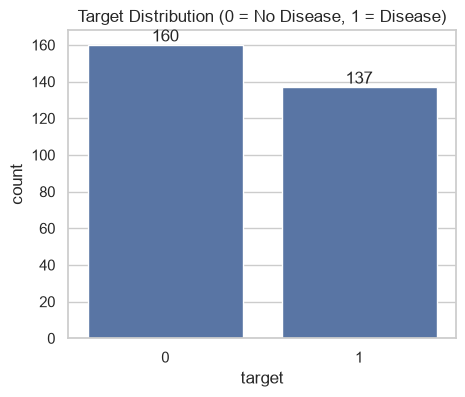

In [11]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="target", ax=ax)
ax.set_title("Target Distribution (0 = No Disease, 1 = Disease)")
for c in ax.containers:
    ax.bar_label(c)
plt.show()

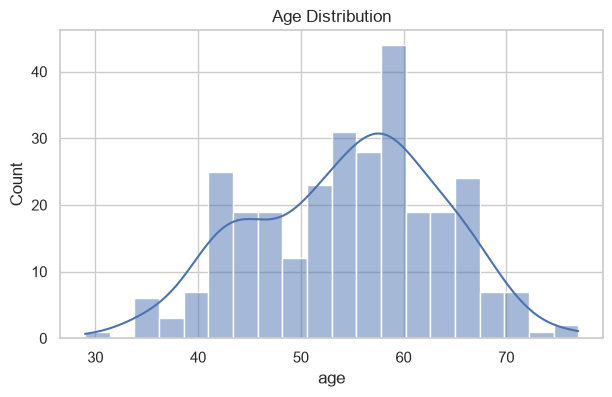

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=df, x="age", bins=20, kde=True, ax=ax)
ax.set_title("Age Distribution")
plt.show()

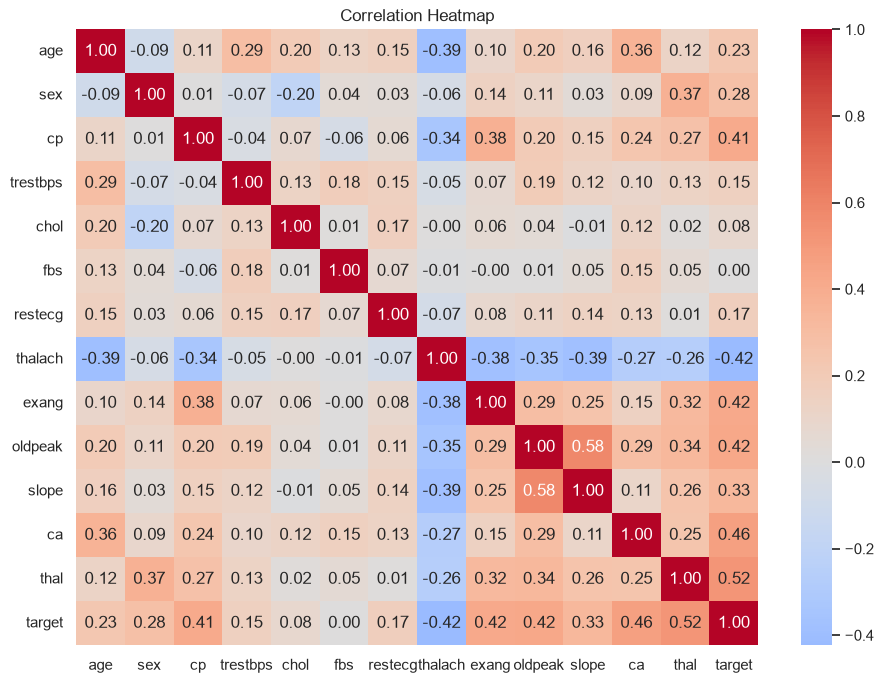

In [13]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

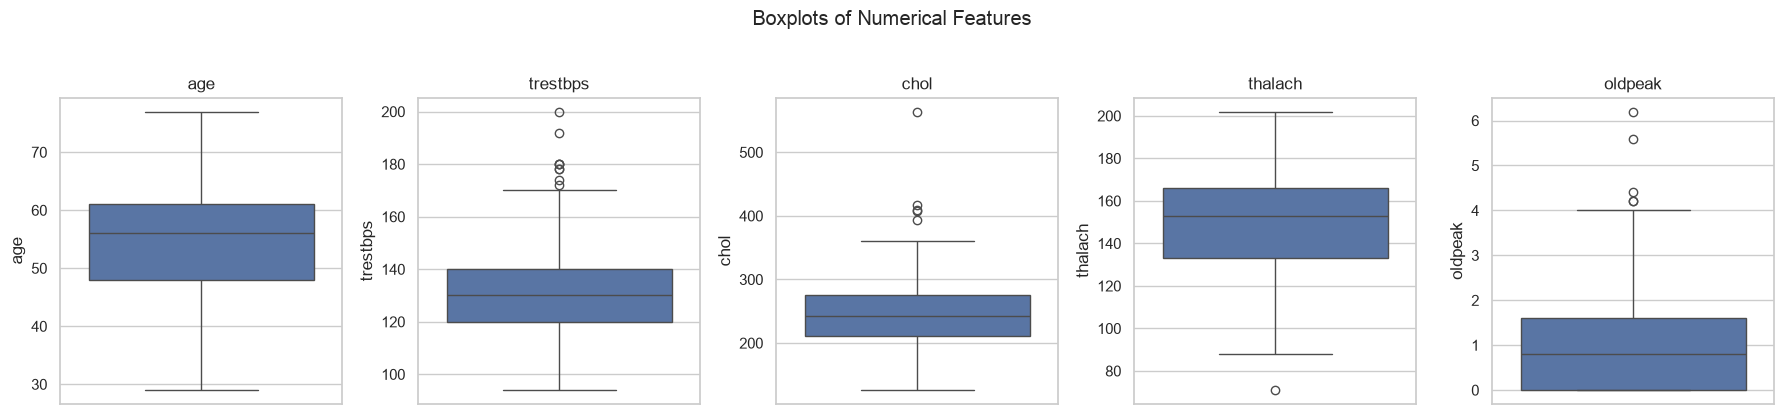

In [14]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Boxplots of Numerical Features", y=1.03)
plt.tight_layout()
plt.show()

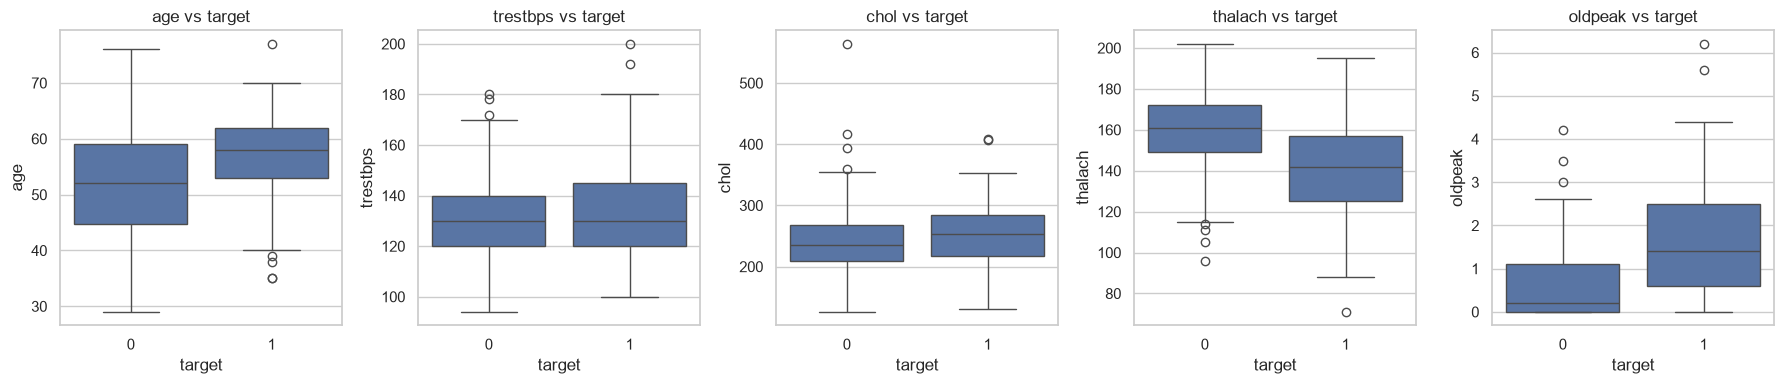

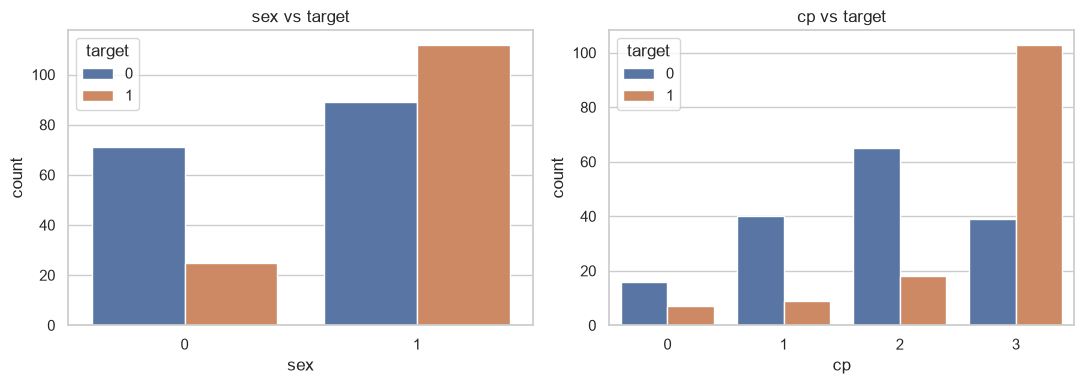

In [15]:
# Numerical features vs target
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="target", y=col, ax=ax)
    ax.set_title(f"{col} vs target")
plt.tight_layout()
plt.show()

# Categorical features vs target
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["sex", "cp"]):
    sns.countplot(data=df, x=col, hue="target", ax=ax)
    ax.set_title(f"{col} vs target")
plt.tight_layout()
plt.show()

# 7. Feature Selection
Only these seven input features are used. Target: `target`.

| Feature | Description |
|---|---|
| age | Age |
| sex | Biological sex encoding |
| cp | Chest pain type |
| trestbps | Resting blood pressure |
| chol | Cholesterol |
| thalach | Maximum heart rate |
| oldpeak | ST depression |

**Why these features?**
- They are cheap, routine measurements available in a basic check-up (no stress test imaging or angiography needed), which makes the model practical to deploy.
- They cover demographics (`age`, `sex`), symptoms (`cp`), vitals (`trestbps`, `thalach`), blood work (`chol`) and an ECG-derived signal (`oldpeak`), all established cardiovascular risk indicators.
- A short feature list is easy for a user to fill in and reduces overfitting on a small dataset.

In [16]:
FEATURES = ["age", "sex", "cp", "trestbps", "chol", "thalach", "oldpeak"]
TARGET = "target"

# Quick check: correlation of the chosen features with the target
df[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(3)

oldpeak     0.424
cp          0.409
sex         0.278
age         0.227
trestbps    0.153
chol        0.080
thalach    -0.424
Name: target, dtype: float64

# 8. Data Preprocessing
- Separate `X` (independent variables) and `y` (dependent variable).
- `cp` (chest pain type) is nominal, so it is **one-hot encoded**. `sex` is already binary (0/1) and passes through unchanged.
- Continuous features (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`) are **standard-scaled**; this matters for Logistic Regression, KNN and SVM.
- The transformer lives inside each `Pipeline`, so it is fitted **only on the training data** and merely applied to the test data, which prevents data leakage.

In [17]:
X = df[FEATURES]
y = df[TARGET]

numeric_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_features = ["cp"]
binary_features = ["sex"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("bin", "passthrough", binary_features),
])
print(X.shape, y.shape)

(297, 7) (297,)


# 9. Train-Test Split
80% train / 20% test, `random_state=42`, `stratify=y`.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class ratio:", y_train.mean().round(3), " Test class ratio:", y_test.mean().round(3))

Train: (237, 7)  Test: (60, 7)
Train class ratio: 0.46  Test class ratio: 0.467


# 10. Model Training
Five classifiers, each wrapped in a Scikit-learn `Pipeline` (preprocessing + model).
Tree-based models don't need scaling, but sharing the same preprocessor keeps the code uniform and is harmless.

In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

pipelines = {}
for name, clf in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", clf)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: KNN


Trained: Random Forest
Trained: SVM (RBF)
Trained: Gradient Boosting


# 11. Model Evaluation
Accuracy, Precision, Recall, F1, confusion matrix and classification report for each model on the held-out test set.

Logistic Regression
              precision    recall  f1-score   support

  No Disease       0.77      0.84      0.81        32
     Disease       0.80      0.71      0.75        28

    accuracy                           0.78        60
   macro avg       0.79      0.78      0.78        60
weighted avg       0.78      0.78      0.78        60

KNN
              precision    recall  f1-score   support

  No Disease       0.77      0.84      0.81        32
     Disease       0.80      0.71      0.75        28

    accuracy                           0.78        60
   macro avg       0.79      0.78      0.78        60
weighted avg       0.78      0.78      0.78        60

Random Forest
              precision    recall  f1-score   support

  No Disease       0.76      0.81      0.79        32
     Disease       0.77      0.71      0.74        28

    accuracy                           0.77        60
   macro avg       0.77      0.76      0.76        60
weighted avg       0.77      0.77   

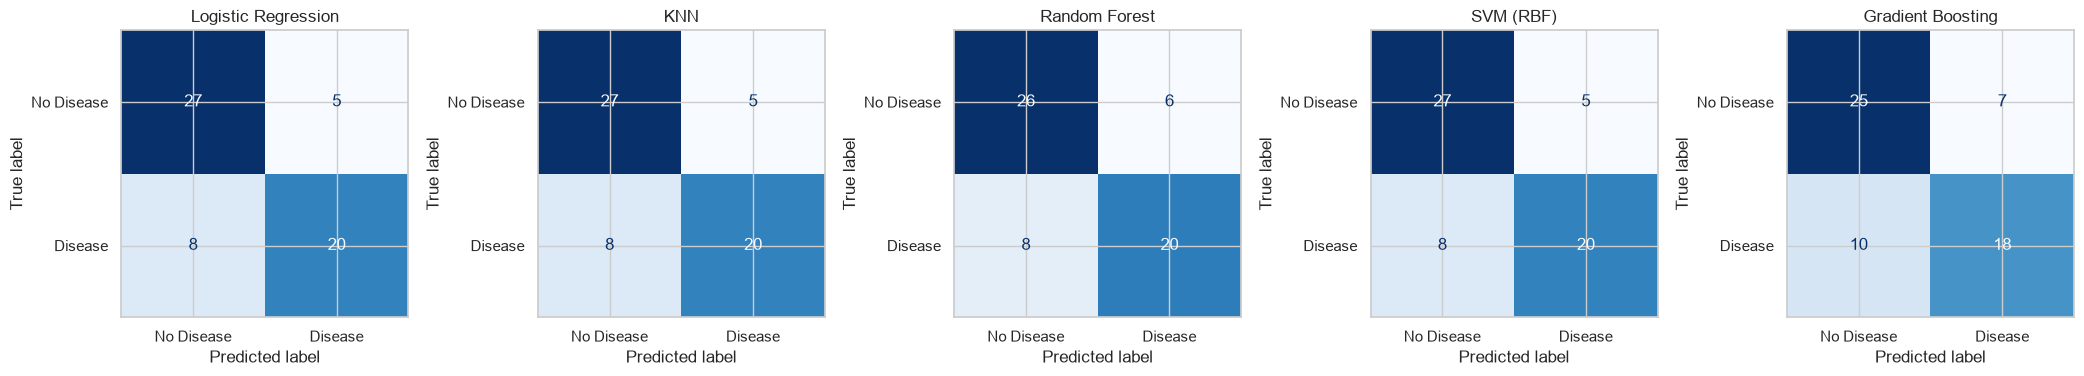

In [20]:
results = []
fig, axes = plt.subplots(1, len(pipelines), figsize=(4.2 * len(pipelines), 4))

for ax, (name, pipe) in zip(axes, pipelines.items()):
    y_pred = pipe.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
    })
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=["No Disease", "Disease"]))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["No Disease", "Disease"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)

plt.tight_layout()
plt.show()

# 12. Model Comparison
In a medical screening setting a **false negative** (missing a sick patient) is costlier than a false positive, so recall matters. Selecting on recall alone would favour a model that predicts "disease" for everyone, so the best model is chosen by **F1-score** (balances precision and recall), with recall as the first tie-breaker, then accuracy.

In [21]:
comparison = (pd.DataFrame(results)
              .sort_values(["F1-score", "Recall", "Accuracy"], ascending=False)
              .reset_index(drop=True))
comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.7833,0.8000,0.7143,0.7547
1,KNN,0.7833,0.8000,0.7143,0.7547
2,SVM (RBF),0.7833,0.8000,0.7143,0.7547
3,Random Forest,0.7667,0.7692,0.7143,0.7407
4,Gradient Boosting,0.7167,0.7200,0.6429,0.6792


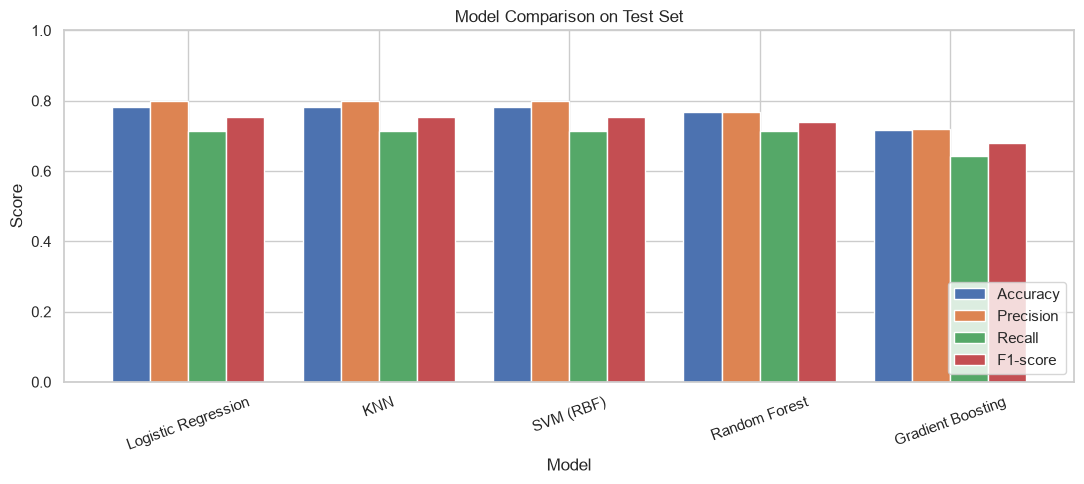

In [22]:
ax = comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(11, 5), width=0.8)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Model Comparison on Test Set")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [23]:
# Sanity check: 5-fold stratified CV F1 on the training set (test set stays untouched)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {n: cross_val_score(p, X_train, y_train, cv=cv, scoring="f1").mean()
             for n, p in pipelines.items()}
pd.Series(cv_scores, name="CV F1 (train)").sort_values(ascending=False).round(4)

Logistic Regression    0.7494
Random Forest          0.7029
Gradient Boosting      0.7010
KNN                    0.6876
SVM (RBF)              0.6870
Name: CV F1 (train), dtype: float64

In [24]:
best_name = comparison.loc[0, "Model"]
best_pipeline = pipelines[best_name]
print("Best model:", best_name)
print(comparison.iloc[[0]].round(4).to_string(index=False))

Best model: Logistic Regression
              Model  Accuracy  Precision  Recall  F1-score
Logistic Regression    0.7833        0.8  0.7143    0.7547


# 13. Save Best Model
The fitted pipeline (preprocessing + model) is saved with joblib, so raw inputs can be passed straight to `predict`. Feature names and metadata go to a JSON file.

In [25]:
joblib.dump(best_pipeline, "../models/heart_disease_model.pkl")

best_row = comparison.loc[0]
metadata = {
    "model_name": best_name,
    "features": FEATURES,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "binary_features": binary_features,
    "target": TARGET,
    "classes": {"0": "No heart disease", "1": "Heart disease"},
    "test_metrics": {k: round(float(best_row[k]), 4) for k in ["Accuracy", "Precision", "Recall", "F1-score"]},
    "train_size": int(len(X_train)),
    "test_size": int(len(X_test)),
    "random_state": RANDOM_STATE,
    "sklearn_version": sklearn.__version__,
    "selection_criterion": "F1-score (tie-breakers: recall, accuracy)",
}
with open("../models/heart_disease_model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print(json.dumps(metadata, indent=2))

{
  "model_name": "Logistic Regression",
  "features": [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
  ],
  "numeric_features": [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
  ],
  "categorical_features": [
    "cp"
  ],
  "binary_features": [
    "sex"
  ],
  "target": "target",
  "classes": {
    "0": "No heart disease",
    "1": "Heart disease"
  },
  "test_metrics": {
    "Accuracy": 0.7833,
    "Precision": 0.8,
    "Recall": 0.7143,
    "F1-score": 0.7547
  },
  "train_size": 237,
  "test_size": 60,
  "random_state": 42,
  "sklearn_version": "1.9.1",
  "selection_criterion": "F1-score (tie-breakers: recall, accuracy)"
}


In [26]:
# Reload and verify with a raw sample
loaded = joblib.load("../models/heart_disease_model.pkl")
sample = pd.DataFrame([{"age": 58, "sex": 1, "cp": 3, "trestbps": 140, "chol": 240, "thalach": 120, "oldpeak": 2.0}])
pred = loaded.predict(sample)[0]
proba = loaded.predict_proba(sample)[0, 1]
print(f"Prediction: {pred} ({metadata['classes'][str(pred)]}), P(disease) = {proba:.2f}")
assert (loaded.predict(X_test) == best_pipeline.predict(X_test)).all()

Prediction: 1 (Heart disease), P(disease) = 0.94
